In [1]:
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [2]:
train_csv = pd.read_csv('archive/fashion-mnist_train.csv')
test_csv = pd.read_csv('archive/fashion-mnist_test.csv')

print(train_csv.head(5))

   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0         0         1   
4       0  ...         0         0         0         0         0         0   

   pixel781  pixel782  pixel783  pixel784  
0         0         0         

In [3]:
X_train = train_csv.iloc[:, 1:]
y_train = train_csv.iloc[:, 0]

X_test = test_csv.iloc[:, 1:]
y_test = test_csv.iloc[:, 0]

In [4]:
X_train

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,5,0,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,1,2,0,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,0,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,0,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
y_train.shape

(60000,)

In [6]:
X_train_tensors = torch.tensor(X_train.values, dtype=torch.float32)
X_test_tensors = torch.tensor(X_test.values, dtype=torch.float32)

y_train_tensors = torch.tensor(y_train, dtype=torch.long)
y_test_tensors = torch.tensor(y_test, dtype=torch.long)

In [7]:
class CustomDataset(Dataset):

    def __init__(self, X, y, transform = None):
        self.features = X
        self.labels = y
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        x = self.features[index]
        if self.transform:
            x = self.transform(x)

        return x, self.labels[index]

In [8]:
# preprocessing

class Normalize():

    def __init__(self):
        pass 

    def __call__(self, features):
        return features/255.0


In [9]:
trainset = CustomDataset(X_train_tensors, y_train_tensors, transform=Normalize())
testset = CustomDataset(X_test_tensors, y_test_tensors, transform=Normalize())

In [10]:
train_loader = DataLoader(trainset, batch_size=8, shuffle=True, pin_memory=False, num_workers=0)
test_loader = DataLoader(testset, batch_size=8, pin_memory=False, num_workers=0)

In [11]:
class Model(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            
            nn.Linear(32, 10)
        )

    def forward(self, X):
        return self.model(X)

In [12]:
device = torch.device(
    "mps"
    if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)
print(f"Using device: {device}")

Using device: mps


In [13]:
model = Model(X_train.shape[1]).to(device) # move model to gpu

In [14]:
from torchinfo import summary

summary(model, X_train.shape, device=device)

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [60000, 10]               --
├─Sequential: 1-1                        [60000, 10]               --
│    └─Linear: 2-1                       [60000, 64]               50,240
│    └─BatchNorm1d: 2-2                  [60000, 64]               128
│    └─ReLU: 2-3                         [60000, 64]               --
│    └─Dropout: 2-4                      [60000, 64]               --
│    └─Linear: 2-5                       [60000, 32]               2,080
│    └─BatchNorm1d: 2-6                  [60000, 32]               64
│    └─ReLU: 2-7                         [60000, 32]               --
│    └─Dropout: 2-8                      [60000, 32]               --
│    └─Linear: 2-9                       [60000, 10]               330
Total params: 52,842
Trainable params: 52,842
Non-trainable params: 0
Total mult-adds (G): 3.17
Input size (MB): 188.16
Forward/backward pass size

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

In [16]:
print(device)
print(next(model.parameters()).device)   # should say mps, not cpu

mps
mps:0


In [17]:
epochs = 20 

for epoch in range(epochs):

    running_loss = 0.0
    epoch_loss = 0.0

    # mode  
    model.train()

    for xb, yb in train_loader:

        xb, yb = xb.to(device), yb.to(device)

        # forward pass
        logits = model(xb)

        # compute loss
        loss = criterion(logits, yb)

        # backward pass
        optimizer.zero_grad()
        loss.backward()

        # update parameters
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss/len(train_loader)


    # mode  
    model.eval()

    test_running_loss = 0.0
    test_epoch_loss = 0.0

    with torch.no_grad():
        for xb, yb in test_loader:

            xb, yb = xb.to(device), yb.to(device)

            # forward pass
            logits = model(xb)

            # compute loss
            loss = criterion(logits, yb)

            test_running_loss += loss.item()

        test_epoch_loss = test_running_loss/len(test_loader)


    print(f'epoch: {epoch+1}/{epochs}, loss = {epoch_loss}, val_loss = {test_epoch_loss}')

epoch: 1/20, loss = 0.7668207788959146, val_loss = 0.44472177728042006
epoch: 2/20, loss = 0.6296134025568764, val_loss = 0.4075770634025335
epoch: 3/20, loss = 0.5966816633149982, val_loss = 0.4005613912761211
epoch: 4/20, loss = 0.5737758332118392, val_loss = 0.3932917338008061
epoch: 5/20, loss = 0.5651987443814676, val_loss = 0.38108026224188507
epoch: 6/20, loss = 0.5494192098617554, val_loss = 0.38044710441678764
epoch: 7/20, loss = 0.5486237982119123, val_loss = 0.38245943714007735
epoch: 8/20, loss = 0.5436818313119313, val_loss = 0.37012755251862106
epoch: 9/20, loss = 0.5402750047450264, val_loss = 0.37731573849394917
epoch: 10/20, loss = 0.5354215726281206, val_loss = 0.39023098366707565
epoch: 11/20, loss = 0.534936435871323, val_loss = 0.3662452759295702
epoch: 12/20, loss = 0.5277024329262475, val_loss = 0.36558073606863617
epoch: 13/20, loss = 0.5288971522960811, val_loss = 0.37219791100248695
epoch: 14/20, loss = 0.5242463951135675, val_loss = 0.36852205438688396
epoch:

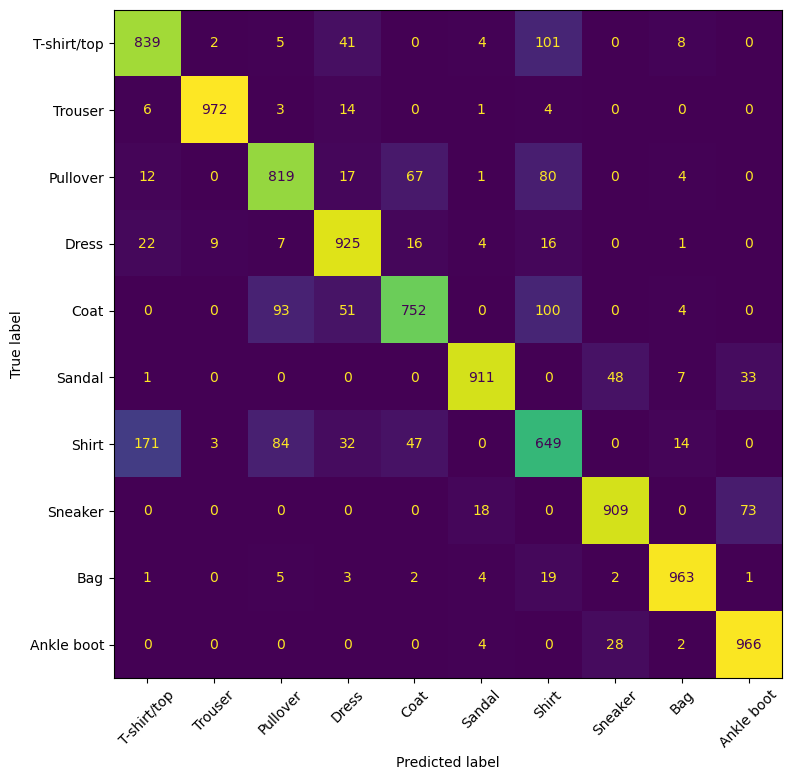

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fashion_mnist_labels = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# mode  
model.eval()

all_targets = []
all_preds = []

with torch.no_grad():
    for xb, yb in test_loader:

        xb, yb = xb.to(device), yb.to(device)

        # forward pass
        logits = model(xb)

        # prediction class
        y_preds = torch.argmax(logits, dim=1)

        all_targets.extend(yb.cpu().flatten().numpy())
        all_preds.extend(y_preds.cpu().flatten().numpy())


cm = confusion_matrix(all_targets, all_preds)
        
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=fashion_mnist_labels).plot(
    ax=ax, xticks_rotation=45, colorbar=False
)
plt.tight_layout()
plt.show()

In [22]:
# set mode 
model.eval()

all_targets_train = []
all_preds_train = []

with torch.no_grad():
    for xb, yb in train_loader:

        xb, yb = xb.to(device), yb.to(device)

        # forward pass
        logits = model(xb)

        # prediction class
        y_preds = torch.argmax(logits, dim=1)

        all_targets_train.extend(yb.cpu().flatten().numpy())
        all_preds_train.extend(y_preds.cpu().flatten().numpy())


In [23]:
from sklearn.metrics import accuracy_score

print(f'train accuracy: {accuracy_score(all_targets_train, all_preds_train)}')
print(f'test accuracy: {accuracy_score(all_targets, all_preds)}')

train accuracy: 0.88165
test accuracy: 0.8705
